In [6]:
import tensorflow as tf
print("Welcome to BloomAI! 🌸")
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

Welcome to BloomAI! 🌸
TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [1]:
!pip install -q tensorflow-datasets

In [2]:
!pip install -q importlib_resources

import importlib_resources
import tensorflow_datasets as tfds

(train_data, val_data, test_data), info = tfds.load(
    'oxford_flowers102',
    split=['train', 'validation', 'test'],
    as_supervised=True,
    with_info=True
)

print("Classes:", info.features['label'].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.SIZ81C_2.1.1/oxford_flowers102-test.tfrecord-…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.SIZ81C_2.1.1/oxford_flowers102-validation.tfr…

Dataset oxford_flowers102 downloaded and prepared to /root/tensorflow_datasets/oxford_flowers102/2.1.1. Subsequent calls will reuse this data.
Classes: 102


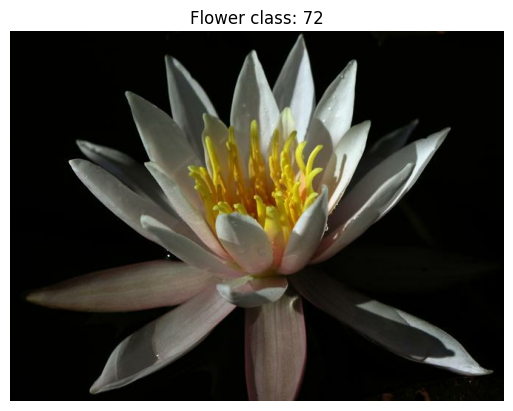

In [3]:
import matplotlib.pyplot as plt

for image, label in train_data.take(1):
    plt.imshow(image)
    plt.title(f"Flower class: {label.numpy()}")
    plt.axis("off")
    plt.show()

In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32

def prepare(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

train_data = train_data.map(prepare).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(prepare).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(prepare).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Images prepared successfully! 🌸")


Images prepared successfully! 🌸


In [7]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

In [9]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Sequential

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.2),
    Dense(102, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 102)            │       130,662 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,180,233 (15.95 MB)

 Trainable params: 130,662 (510.40 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 59s 950ms/step - accuracy: 0.1039 - loss: 4.2951 - val_accuracy: 0.4451 - val_loss: 3.5060
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.6255 - loss: 2.8919 - val_accuracy: 0.6716 - val_loss: 2.5926
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.8294 - loss: 2.0199 - val_accuracy: 0.7441 - val_loss: 1.9981
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.8882 - loss: 1.4737 - val_accuracy: 0.7922 - val_loss: 1.6218
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 0.9353 - loss: 1.0922 - val_accuracy: 0.8088 - val_loss: 1.3767


In [11]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

193/193 ━━━━━━━━━━━━━━━━━━━━ 19s 100ms/step - accuracy: 0.7915 - loss: 1.4863
Test Accuracy: 79.15 %


In [12]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

y_true = np.concatenate([y.numpy() for _, y in test_data])
y_pred = model.predict(test_data)

y_pred_classes = np.argmax(y_pred, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred_classes))
print("Top-5 Accuracy:", top_k_accuracy_score(
    y_true, y_pred, k=5, labels=np.arange(102)
))
print("F1-Score:", f1_score(y_true, y_pred_classes, average="macro"))

193/193 ━━━━━━━━━━━━━━━━━━━━ 23s 90ms/step
Accuracy: 0.7915108147666288
Top-5 Accuracy: 0.9339730037404456
F1-Score: 0.7789538194490995


In [13]:
model.save("bloomai_model.keras")

In [14]:
from google.colab import files

files.download("bloomai_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
!pip install -q gradio


In [18]:
import gradio as gr
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds

labels = tfds.builder("oxford_flowers102").info.features["label"].names

def predict_flower(image):
    image = tf.image.resize(image, (224, 224))
    image = tf.expand_dims(image, 0)

    predictions = model.predict(image, verbose=0)[0]
    top = np.argsort(predictions)[-5:][::-1]

    return {labels[i]: float(predictions[i]) for i in top}

demo = gr.Interface(
    fn=predict_flower,
    inputs=gr.Image(type="numpy"),
    outputs=gr.Label(num_top_classes=5),
    title="BloomAI 🌸",
    description="Upload a flower image to identify its species."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://727653a503922ddc8c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [17]:
import tensorflow_datasets as tfds

builder = tfds.builder("oxford_flowers102")
labels = builder.info.features["label"].names

print("Total flower classes:", len(labels))
print("Example labels:", labels[:10])

Total flower classes: 102
Example labels: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle']


In [19]:
import os
print(os.listdir('/content'))

['.config', 'bloomai_model.keras', '.gradio', 'sample_data']


In [20]:
from google.colab import files
files.download('/content/bloomai_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>